# Segmentación de un glioblastoma por agrupamiento

Este cuaderno segmenta un glioblastoma en resonancia magnética sin una segmentación de referencia, agrupando
los píxeles según sus intensidades en tres secuencias.

1. Cargar las tres secuencias y aislar el cerebro.
2. Ver cada píxel como un punto del espacio de características.
3. Agrupar con k-means escrito desde cero y elegir el número de grupos.
4. Agrupar con fuzzy c-means y pasar del mapa de pertenencia al contorno del tumor.
5. Comparar con una mezcla de gaussianas.
6. Eliminar los píxeles sueltos con un campo aleatorio de Markov.

In [1]:
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi

plt.rcParams.update({"figure.figsize": (6, 4.5), "font.size": 12})
COLORES = np.array(["#3C72E8", "#006400", "#E85C3C", "#8C1515", "#A01FEF"])

def sin_ejes(ax, titulo=None):
    ax.set_xticks([]); ax.set_yticks([])
    if titulo:
        ax.set_title(titulo, fontsize=12)

## Las imágenes

Son tres secuencias de un mismo corte axial de un paciente con glioblastoma, registradas entre sí, de
$512 \times 512$ píxeles con valores de 0 a 255.

- **T1 con contraste** (gadolinio). El borde activo del tumor capta el contraste y se ve brillante.
- **T1 FLAIR.**
- **T2 FLAIR.** El edema que rodea al tumor se ve brillante.

El mismo píxel corresponde al mismo punto del cerebro en las tres imágenes.

In [2]:
URL = "https://raw.githubusercontent.com/aavelozb/aavelozb.github.io/main/data/gbm-im17/"
SECUENCIAS = [("IM17_axt1c.tiff", "T1 con contraste"), ("IM17_axt1FLAIR.tiff", "T1 FLAIR"),
              ("IM17_axt2FLAIR.tiff", "T2 FLAIR")]
for f, _ in SECUENCIAS:
    if not os.path.exists(f):
        urllib.request.urlretrieve(URL + f, f)
VOL = np.dstack([np.array(Image.open(f).convert("L")).astype(float) for f, _ in SECUENCIAS])
print("Tamaño:", VOL.shape)

Tamaño: (512, 512, 3)


## La región de análisis

El cráneo y la grasa del cuero cabelludo son tan brillantes como el tumor, y hay que descartarlos. Se
umbraliza la imagen suavizada para obtener la cabeza, se rellenan sus huecos, se erosiona con un disco
para quitar el borde y se conserva la región conexa más grande.

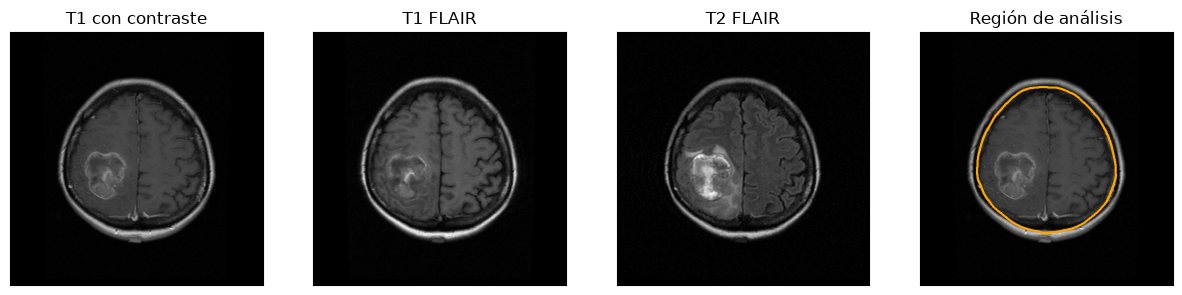

Píxeles del cerebro: 63640


In [3]:
def disco(r):
    y, x = np.ogrid[-r:r + 1, -r:r + 1]
    return x*x + y*y <= r*r

cabeza = ndi.binary_fill_holes(ndi.gaussian_filter(VOL[:, :, 0], 2) > 25)
erosion = ndi.binary_erosion(cabeza, disco(20))
lab, n = ndi.label(erosion)
CEREBRO = lab == 1 + np.argmax(ndi.sum(erosion, lab, range(1, n + 1)))

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, k in zip(ax, range(3)):
    a.imshow(VOL[:, :, k], cmap="gray", vmin=0, vmax=255); sin_ejes(a, SECUENCIAS[k][1])
ax[3].imshow(VOL[:, :, 0], cmap="gray", vmin=0, vmax=255)
ax[3].contour(CEREBRO, levels=[0.5], colors=["orange"], linewidths=1.5); sin_ejes(ax[3], "Región de análisis")
plt.show()
print("Píxeles del cerebro:", CEREBRO.sum())

## Cada píxel es un punto

Con una secuencia, cada píxel es un número y el espacio de características es el histograma. Con dos
secuencias, cada píxel es un punto del plano y aparecen nubes que ninguna secuencia separa por sí sola.

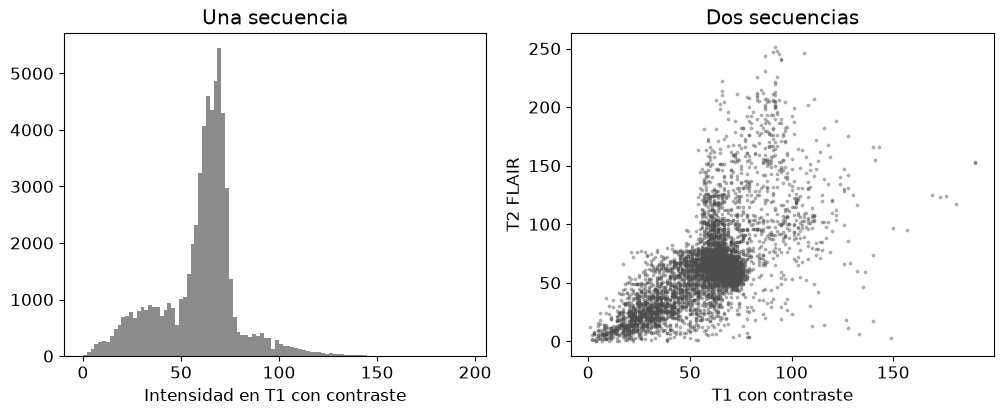

In [4]:
XYZ = VOL[CEREBRO]                     # n x 3, un píxel por fila
X2 = XYZ[:, [0, 2]]                    # T1 con contraste y T2 FLAIR
SUB = np.random.default_rng(0).choice(len(X2), 6000, replace=False)   # submuestra para dibujar

def a_imagen(valores, relleno=np.nan):
    salida = np.full(CEREBRO.shape, relleno, dtype=float); salida[CEREBRO] = valores
    return salida

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(XYZ[:, 0], bins=100, color="0.55"); ax[0].set_xlabel("Intensidad en T1 con contraste"); ax[0].set_title("Una secuencia")
ax[1].scatter(X2[SUB, 0], X2[SUB, 1], s=3, color="0.3", alpha=0.35)
ax[1].set_xlabel("T1 con contraste"); ax[1].set_ylabel("T2 FLAIR"); ax[1].set_title("Dos secuencias")
plt.show()

## k-means desde cero

El algoritmo de Lloyd alterna dos pasos hasta que la partición no cambia.

1. **Asignar** cada punto al centroide más cercano.
2. **Actualizar** cada centroide como la media de sus puntos.

Cada paso baja la suma de cuadrados dentro de los grupos, $J = \sum_k\sum_{i \in C_k}\|\mathbf{x}_i - \boldsymbol\mu_k\|^2$.
Para ver el recorrido, los cuatro centroides parten sobre la diagonal, lejos de los datos.

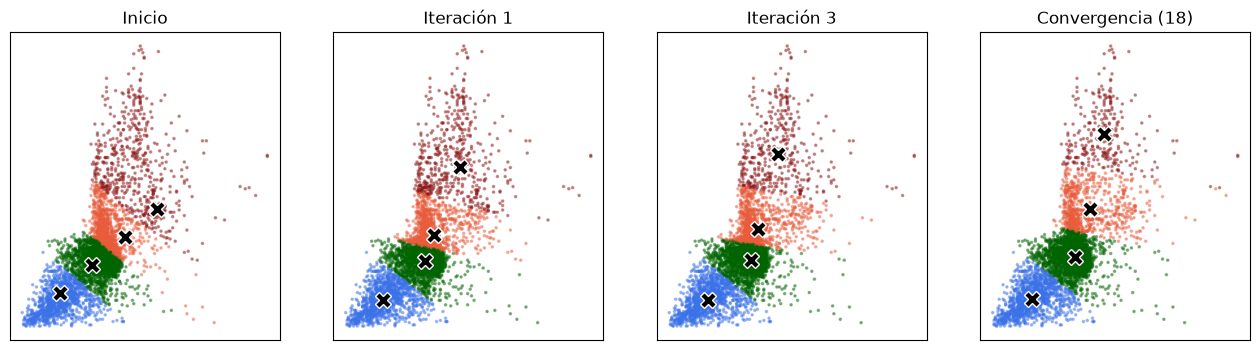

In [5]:
def kmeans(X, K, V0=None, semilla=0, iteraciones=100):
    r = np.random.default_rng(semilla)
    V = X[r.choice(len(X), K, replace=False)].astype(float) if V0 is None else np.array(V0, float)
    historia, J, etiquetas = [V.copy()], [], None
    for _ in range(iteraciones):
        d = ((X[:, None, :] - V[None])**2).sum(-1)
        nuevas = d.argmin(1)
        J.append(d[np.arange(len(X)), nuevas].sum())
        for k in range(K):
            if np.any(nuevas == k):
                V[k] = X[nuevas == k].mean(0)
        historia.append(V.copy())
        if etiquetas is not None and np.array_equal(nuevas, etiquetas):
            break
        etiquetas = nuevas
    return etiquetas, V, historia, J

K = 4
V0 = np.array([[30., 30.], [55., 55.], [80., 80.], [105., 105.]])
Xs = X2[SUB]
_, _, hist, J = kmeans(Xs, K, V0=V0)
pasos = [0, 1, 3, len(hist) - 1]
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, t in zip(ax, pasos):
    V = hist[t]; l = ((Xs[:, None, :] - V[None])**2).sum(-1).argmin(1)
    a.scatter(Xs[:, 0], Xs[:, 1], s=2.5, c=COLORES[l], alpha=0.4)
    a.plot(*V.T, "X", color="k", ms=12, mec="w")
    sin_ejes(a, "Inicio" if t == 0 else ("Convergencia (%d)" % t if t == pasos[-1] else "Iteración %d" % t))
plt.show()

Ahora con todos los píxeles. Los grupos se ordenan por la intensidad media en T1 con contraste, de modo que
el último grupo es el de mayor realce.

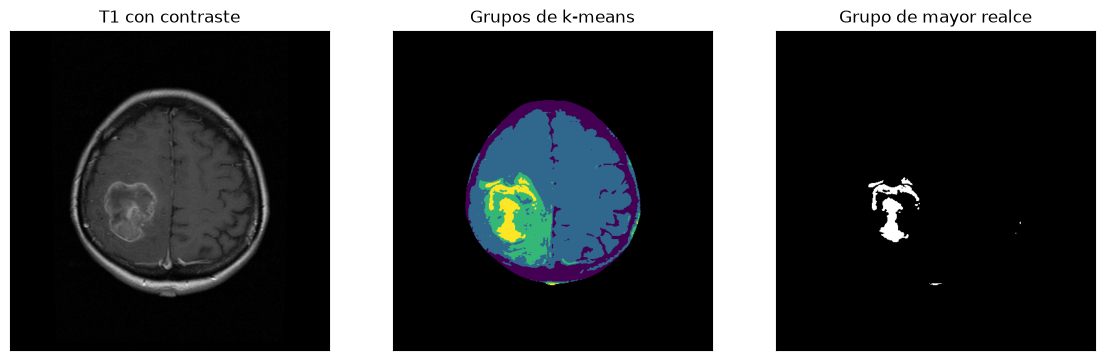

Centroides (T1 con contraste, T2 FLAIR):
 [[ 31.5  24.4]
 [ 64.2  62. ]
 [ 76.  103.3]
 [ 88.9 169.9]]
Componentes conexas del grupo de mayor realce: 12


In [6]:
lab_km, V_km, _, _ = kmeans(X2, K, V0=V0)
orden = np.argsort(V_km[:, 0]); remap = np.empty(K, int); remap[orden] = np.arange(K)
lab_km, V_km = remap[lab_km], V_km[orden]
E_km = a_imagen(lab_km, -1)
tumor_km = E_km == K - 1
fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
ax[0].imshow(VOL[:, :, 0], cmap="gray"); sin_ejes(ax[0], "T1 con contraste")
ax[1].imshow(np.ma.masked_where(E_km < 0, E_km), cmap="viridis"); ax[1].set_facecolor("black"); sin_ejes(ax[1], "Grupos de k-means")
ax[2].imshow(tumor_km, cmap="gray"); sin_ejes(ax[2], "Grupo de mayor realce")
plt.show()
print("Centroides (T1 con contraste, T2 FLAIR):\n", V_km.round(1))
print("Componentes conexas del grupo de mayor realce:", ndi.label(tumor_km, structure=np.ones((3, 3)))[1])

El grupo de mayor realce contiene el tumor, pero también píxeles sueltos en el resto del cerebro. k-means
decide cada píxel por sus intensidades, sin mirar a sus vecinos.

Como verificación, scikit-learn llega prácticamente a la misma partición. Las pocas diferencias son píxeles
del borde entre dos grupos, que dependen del criterio de detención.

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

sk = KMeans(K, init=V0, n_init=1).fit(X2)
print("Índice de Rand ajustado entre nuestra partición y la de scikit-learn:", adjusted_rand_score(lab_km, sk.labels_))

Índice de Rand ajustado entre nuestra partición y la de scikit-learn: 0.9985359113295967


## ¿Cuántos grupos?

$J$ siempre baja al agregar grupos, así que no sirve sola para elegir $K$. Se busca un codo en la curva y se
mira la silueta media, que compara la distancia de cada punto a su grupo con la distancia al grupo vecino.

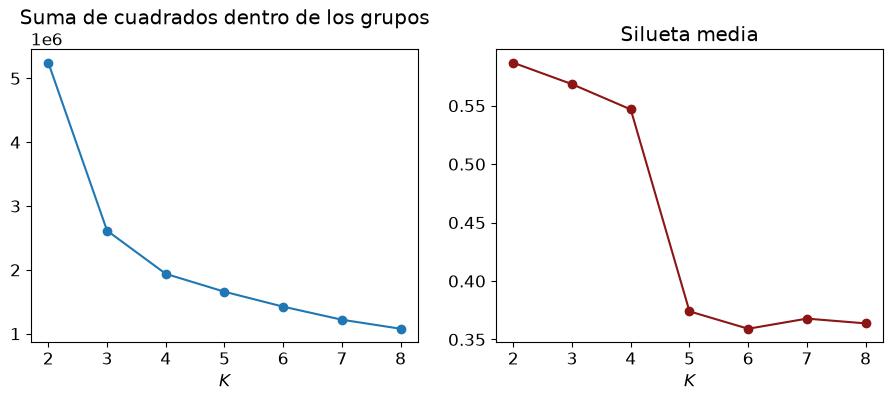

In [8]:
from sklearn.metrics import silhouette_score

Ks = range(2, 9); inercias, siluetas = [], []
for k in Ks:
    km = KMeans(k, n_init=10, random_state=0).fit(Xs)
    inercias.append(km.inertia_); siluetas.append(silhouette_score(Xs, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(list(Ks), inercias, "o-"); ax[0].set_xlabel("$K$"); ax[0].set_title("Suma de cuadrados dentro de los grupos")
ax[1].plot(list(Ks), siluetas, "o-", color="#8C1515"); ax[1].set_xlabel("$K$"); ax[1].set_title("Silueta media")
plt.show()

Aquí la silueta es máxima con $K = 2$ y cae con fuerza después de $K = 4$. Los índices dan una orientación,
no una respuesta. En una imagen médica el número de grupos también se
elige con el conocimiento de los tejidos presentes: líquido cefalorraquídeo, sustancia blanca, sustancia
gris con edema y tumor que realza.

## Fuzzy c-means desde cero

En el borde entre dos tejidos, un píxel contiene un poco de cada uno. Fuzzy c-means asigna a cada píxel un
grado de pertenencia $u_{ik} \in [0, 1]$ a cada grupo, con $\sum_k u_{ik} = 1$, y minimiza
$$J_m = \sum_{i}\sum_{k}u_{ik}^{\,m}\,\|\mathbf{x}_i - \mathbf{v}_k\|^2, \qquad m > 1 .$$
Las dos actualizaciones son
$$\mathbf{v}_k = \frac{\sum_i u_{ik}^{\,m}\mathbf{x}_i}{\sum_i u_{ik}^{\,m}}, \qquad
u_{ik} = \left[\sum_{j}\left(\frac{\|\mathbf{x}_i - \mathbf{v}_k\|}{\|\mathbf{x}_i - \mathbf{v}_j\|}\right)^{2/(m-1)}\right]^{-1}.$$

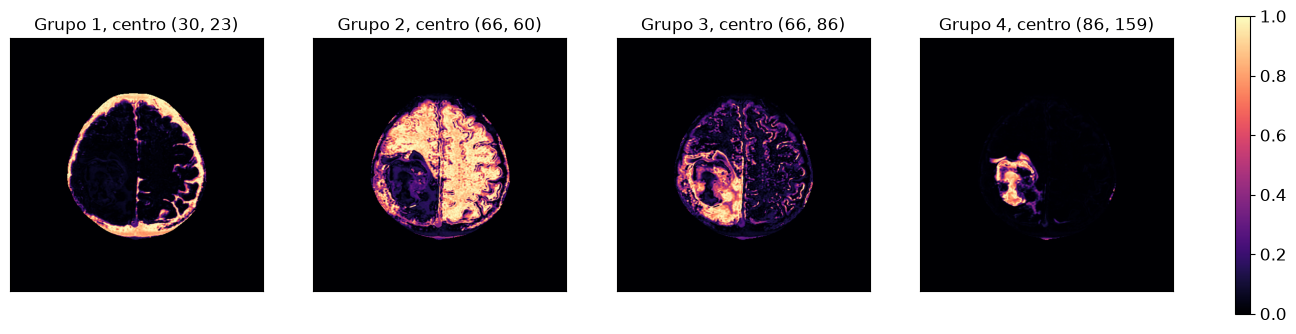

Fracción de píxeles con pertenencia máxima menor que 0,6: 0.188


In [9]:
def fcm(X, K, V0, m=2.0, iteraciones=300, tol=1e-5):
    V = np.array(V0, float)
    for _ in range(iteraciones):
        d2 = ((X[:, None, :] - V[None])**2).sum(-1) + 1e-10
        U = 1.0/((d2[:, :, None]/d2[:, None, :])**(1/(m - 1))).sum(-1)
        Vn = ((U**m).T @ X)/(U**m).sum(0)[:, None]
        if np.max(np.abs(Vn - V)) < tol:
            return U, Vn
        V = Vn
    return U, V

U, V_fcm = fcm(X2, K, V_km)
fig, ax = plt.subplots(1, K, figsize=(16, 4))
for k, a in enumerate(ax):
    h = a.imshow(a_imagen(U[:, k], 0), cmap="magma", vmin=0, vmax=1)
    sin_ejes(a, "Grupo %d, centro (%d, %d)" % (k + 1, round(V_fcm[k, 0]), round(V_fcm[k, 1])))
fig.colorbar(h, ax=ax, fraction=0.012)
plt.show()
print("Fracción de píxeles con pertenencia máxima menor que 0,6:", np.mean(U.max(1) < 0.6).round(3))

## Del mapa de pertenencia al contorno

1. Umbralizar la pertenencia al grupo del tumor.
2. Cerrar con un disco, para unir el anillo de realce.
3. Rellenar los huecos, para incluir el centro necrótico, que no capta contraste.
4. Conservar la región conexa más grande y dibujar su borde.

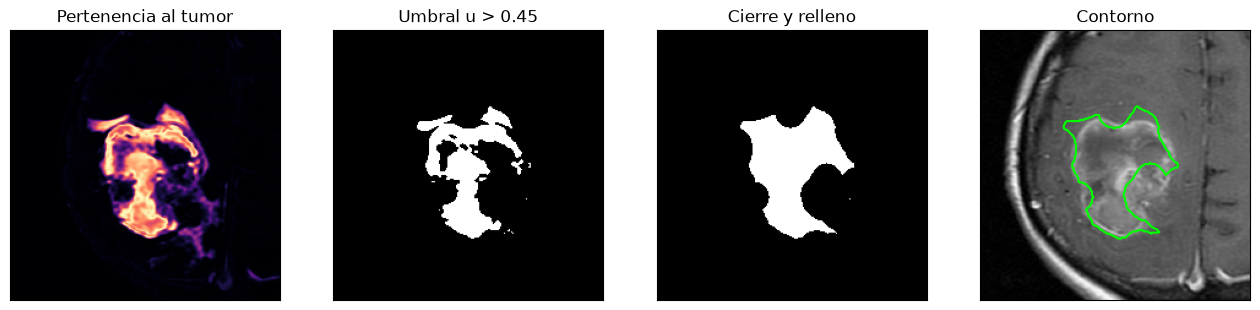

Área del tumor (píxeles): 5057


In [10]:
LAMBDA = 0.45
u_tumor = a_imagen(U[:, -1], 0)

def contorno(u, umbral=LAMBDA):
    m = ndi.binary_fill_holes(ndi.binary_closing(u > umbral, disco(12)))
    l, n = ndi.label(m)
    return l == 1 + np.argmax(ndi.sum(m, l, range(1, n + 1)))

final = contorno(u_tumor)
cy, cx = np.argwhere(final).mean(0).astype(int)
W = (slice(max(cy - 110, 0), cy + 110), slice(max(cx - 110, 0), cx + 110))   # ventana alrededor del tumor
fig, ax = plt.subplots(1, 4, figsize=(16, 4.2))
ax[0].imshow(u_tumor[W], cmap="magma", vmin=0, vmax=1); sin_ejes(ax[0], "Pertenencia al tumor")
ax[1].imshow((u_tumor > LAMBDA)[W], cmap="gray"); sin_ejes(ax[1], "Umbral u > %.2f" % LAMBDA)
ax[2].imshow(ndi.binary_fill_holes(ndi.binary_closing(u_tumor > LAMBDA, disco(12)))[W], cmap="gray"); sin_ejes(ax[2], "Cierre y relleno")
ax[3].imshow(VOL[:, :, 0][W], cmap="gray"); ax[3].contour(final[W], levels=[0.5], colors=["lime"], linewidths=1.5)
sin_ejes(ax[3], "Contorno")
plt.show()
print("Área del tumor (píxeles):", final.sum())

## Una, dos o tres secuencias

El mismo procedimiento con sólo T1 con contraste, con dos secuencias y con las tres. El índice de Dice,
$2|A \cap B|/(|A| + |B|)$, mide cuánto coinciden dos contornos.

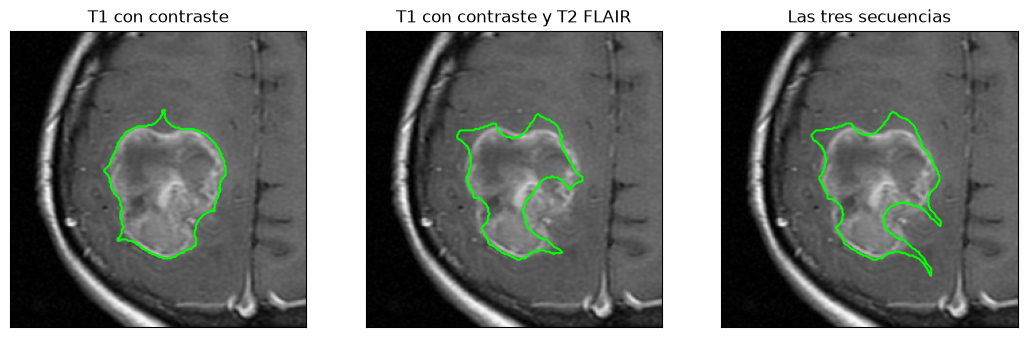

Áreas: 6435 5057 6168
Dice entre una y dos secuencias: 0.805  entre dos y tres: 0.901


In [11]:
def tumor(X, V0):
    U_, V_ = fcm(X, K, V0)
    return contorno(a_imagen(U_[:, np.argmax(V_[:, 0])], 0))

def dice(a, b):
    return 2*np.sum(a & b)/(a.sum() + b.sum())

X1 = XYZ[:, [0]]
t1 = tumor(X1, np.linspace(X1.min(), X1.max(), K)[:, None])
t2 = tumor(X2, V0)
t3 = tumor(XYZ, np.column_stack([np.linspace(XYZ[:, j].min(), XYZ[:, j].max(), K) for j in range(3)]))
fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
for a, t, tit in zip(ax, [t1, t2, t3], ["T1 con contraste", "T1 con contraste y T2 FLAIR", "Las tres secuencias"]):
    a.imshow(VOL[:, :, 0][W], cmap="gray"); a.contour(t[W], levels=[0.5], colors=["lime"], linewidths=1.5); sin_ejes(a, tit)
plt.show()
print("Áreas:", t1.sum(), t2.sum(), t3.sum())
print("Dice entre una y dos secuencias:", round(dice(t1, t2), 3), " entre dos y tres:", round(dice(t2, t3), 3))

## Mezcla de gaussianas

Una mezcla de gaussianas ajustada por el algoritmo EM da, para cada píxel, la probabilidad de cada tejido.
A diferencia de k-means, cada grupo tiene su propia forma (una elipse) y su propia proporción.

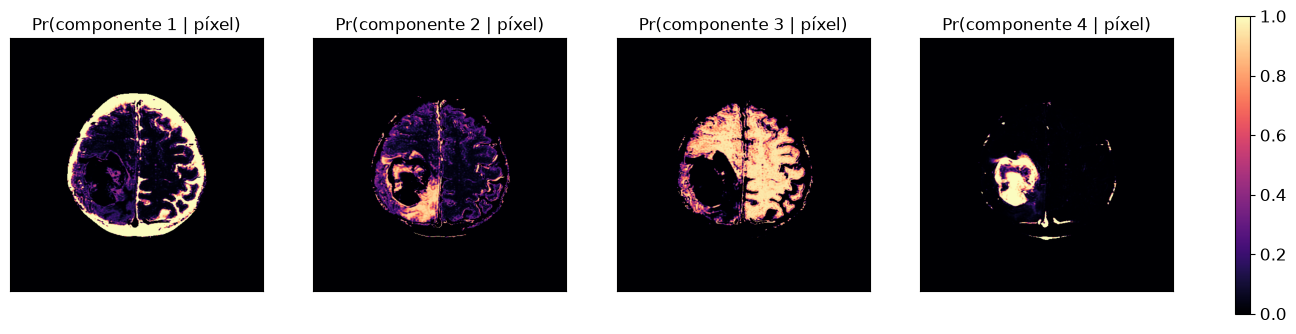

Rand ajustado entre la mezcla y k-means: 0.51


In [12]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(K, covariance_type="full", random_state=2).fit(X2)
o = np.argsort(gm.means_[:, 0]); P = gm.predict_proba(X2)[:, o]
fig, ax = plt.subplots(1, K, figsize=(16, 4))
for k, a in enumerate(ax):
    h = a.imshow(a_imagen(P[:, k], 0), cmap="magma", vmin=0, vmax=1); sin_ejes(a, "Pr(componente %d | píxel)" % (k + 1))
fig.colorbar(h, ax=ax, fraction=0.012)
plt.show()
print("Rand ajustado entre la mezcla y k-means:", round(adjusted_rand_score(lab_km, P.argmax(1)), 3))

## Campos aleatorios de Markov

Ningún método anterior usa la posición de los píxeles. Un campo aleatorio de Markov agrega la preferencia
por que los vecinos tengan la misma etiqueta. La segmentación minimiza la energía
$$E(\mathbf{x}) = \sum_{s}D_s(x_s) + \beta\sum_{\{s,r\}\ \text{vecinos}}\mathbf{1}\{x_s \neq x_r\},$$
donde $D_s(k) = \frac{1}{2}(\mathbf{y}_s - \boldsymbol\mu_k)^\top\boldsymbol\Sigma_k^{-1}(\mathbf{y}_s - \boldsymbol\mu_k) + \frac{1}{2}\log|\boldsymbol\Sigma_k|$
mide cuánto se aleja el píxel $s$ de la clase $k$, y $\beta$ fija cuánto pesan los vecinos.

El **modo condicional iterado** (ICM) asigna a cada píxel la etiqueta que minimiza su propia energía con los
vecinos fijos, $x_s \leftarrow \arg\min_k\,[D_s(k) + \beta\,n_s(k)]$, donde $n_s(k)$ es el número de vecinos con
etiqueta distinta de $k$. Los píxeles se actualizan por colores (los de igual paridad de fila y columna no son
vecinos), y así cada actualización no sube la energía.

beta = 0.0: componentes conexas del grupo de mayor realce = 12


beta = 1.0: componentes conexas del grupo de mayor realce = 8


beta = 3.0: componentes conexas del grupo de mayor realce = 5


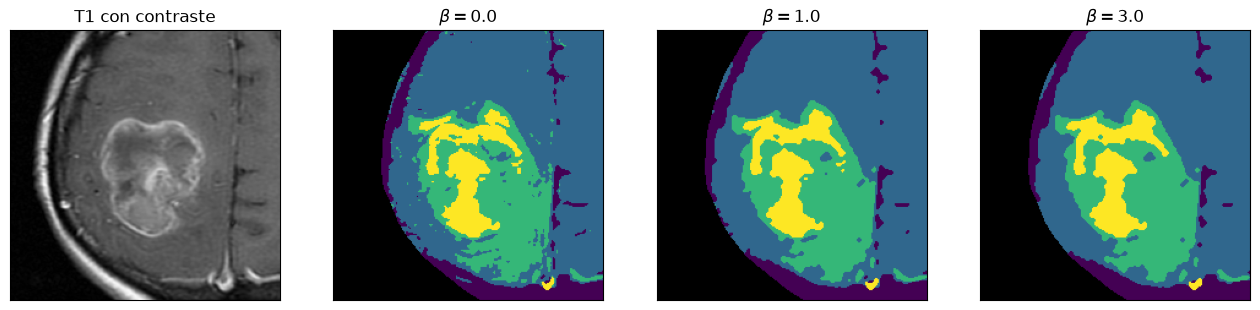

In [13]:
VEC = [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]

def termino_datos(Y, mu, S):
    D = np.empty((len(mu),) + Y.shape[:2])
    for k in range(len(mu)):
        d = Y - mu[k]
        D[k] = 0.5*np.einsum("hwi,ij,hwj->hw", d, np.linalg.inv(S[k]), d) + 0.5*np.log(np.linalg.det(S[k]))
    return D

def icm(D, beta, mascara, barridos=30):
    Kc, H, Wd = D.shape
    x = np.where(mascara, D.argmin(0), -1)
    yy, xx = np.mgrid[:H, :Wd]
    colores = [(yy % 2 == a) & (xx % 2 == b) for a in (0, 1) for b in (0, 1)]
    for _ in range(barridos):
        cambios = 0
        for c in colores:
            P_ = np.pad(x, 1, constant_values=-1)
            iguales = np.zeros((Kc, H, Wd)); nv = np.zeros((H, Wd))
            for dy, dx in VEC:
                v = P_[1 + dy:1 + dy + H, 1 + dx:1 + dx + Wd]
                nv += v >= 0
                for k in range(Kc):
                    iguales[k] += v == k
            nuevo = (D + beta*(nv[None] - iguales)).argmin(0)
            sel = c & mascara
            cambios += np.sum(x[sel] != nuevo[sel]); x[sel] = nuevo[sel]
        if cambios == 0:
            break
    return x

mu_k = np.array([X2[lab_km == k].mean(0) for k in range(K)])
S_k = np.array([np.cov(X2[lab_km == k].T) + 1e-3*np.eye(2) for k in range(K)])
D = termino_datos(VOL[:, :, [0, 2]], mu_k, S_k)
fig, ax = plt.subplots(1, 4, figsize=(16, 4.2))
ax[0].imshow(VOL[:, :, 0][W], cmap="gray"); sin_ejes(ax[0], "T1 con contraste")
for a, beta in zip(ax[1:], [0.0, 1.0, 3.0]):
    x = icm(D, beta, CEREBRO)
    a.imshow(np.ma.masked_where(x < 0, x)[W], cmap="viridis", vmin=0, vmax=K - 1); a.set_facecolor("black")
    sin_ejes(a, r"$\beta = %.1f$" % beta)
    print(f"beta = {beta}: componentes conexas del grupo de mayor realce = {ndi.label(x == K - 1, structure=np.ones((3, 3)))[1]}")
plt.show()

Con $\beta = 0$ cada píxel se decide solo y se recupera la clasificación por intensidades. Al subir $\beta$
desaparecen los píxeles sueltos. Con $\beta$ muy grande el modelo empieza a borrar estructuras finas.

## Ejercicios

1. Repita k-means con $K = 3$ y $K = 5$. ¿Qué tejido se une o se divide?
2. Cambie el umbral $\lambda$ del contorno a 0,3 y a 0,6. ¿Cuánto cambia el área del tumor?
3. Cambie el exponente de fuzzy c-means a $m = 1{,}2$ y a $m = 4$, y compare los mapas de pertenencia.
4. Use la mezcla de gaussianas, en lugar de k-means, para calcular las medias y covarianzas de cada clase
   antes de ICM.
5. Aplique ICM con las tres secuencias en lugar de dos.